# ATDL Phase 6 — Final Evaluation

Compare validation metrics produced in Phases 3 and 5. Select the checkpoint by the highest mean AP50 across the four less represented defect classes (crazing, pitted_surface, rolled-in_scale, scratches), breaking ties with overall validation mAP50. Then evaluate only that selected checkpoint on the held-out test split once. Test metrics are never used for model selection.

## 1. Project, validation reports, and final-test settings

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "requirements-local.txt").is_file() and (p / "results").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the atdl_final_project folder in VS Code.")
RESULTS = PROJECT_ROOT / "results"
PHASE3_METRICS = RESULTS / "phase3_baseline_metrics.json"
PHASE5_METRICS = RESULTS / "phase5_validation_comparison.csv"
DATA_YAML = PROJECT_ROOT / "configs" / "neu_det_yolo.yaml"
SPLIT_MANIFEST = PROJECT_ROOT / "data" / "splits" / "phase2_image_split.csv"
SELECTION_PATH = RESULTS / "selected_model.json"
FINAL_TEST_PATH = RESULTS / "final_test_metrics.json"
RUN_FINAL_TEST = True
IMAGE_SIZE, BATCH_SIZE = 640, 16
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("Validation-based automatic selection enabled; final test enabled:", RUN_FINAL_TEST)

Validation-based automatic selection enabled; final test enabled: True


## 2. Collect and compare validation results

,experiment,AP50_crazing,AP50_pitted_surface,AP50_rolled-in_scale,AP50_scratches,minority_macro_AP50,metrics/mAP50(B)
0,E0_baseline,0.465682,0.833127,0.568346,0.906142,0.693324,0.757753
1,E1_mild_standard,0.428636,0.799987,0.552431,0.908927,0.672495,0.741969
2,E3_targeted_augmentation,0.352285,0.769056,0.461326,0.845197,0.606966,0.687216
3,E4_combined,0.366389,0.764415,0.466970,0.818711,0.604121,0.689874
4,E2_repeat_factor,0.283768,0.724878,0.532435,0.864419,0.601375,0.685498
5,E1_imbalanced_standard,0.297749,0.772400,0.466350,0.815871,0.588093,0.685249
6,E1_severe_standard,0.252253,0.799227,0.479093,0.746948,0.569380,0.664679


Selected from validation: E0_baseline
Checkpoint: ./outputs/checkpoints/phase3_baseline/E0_baseline/weights/best.pt
Selection record: ./results/selected_model.json


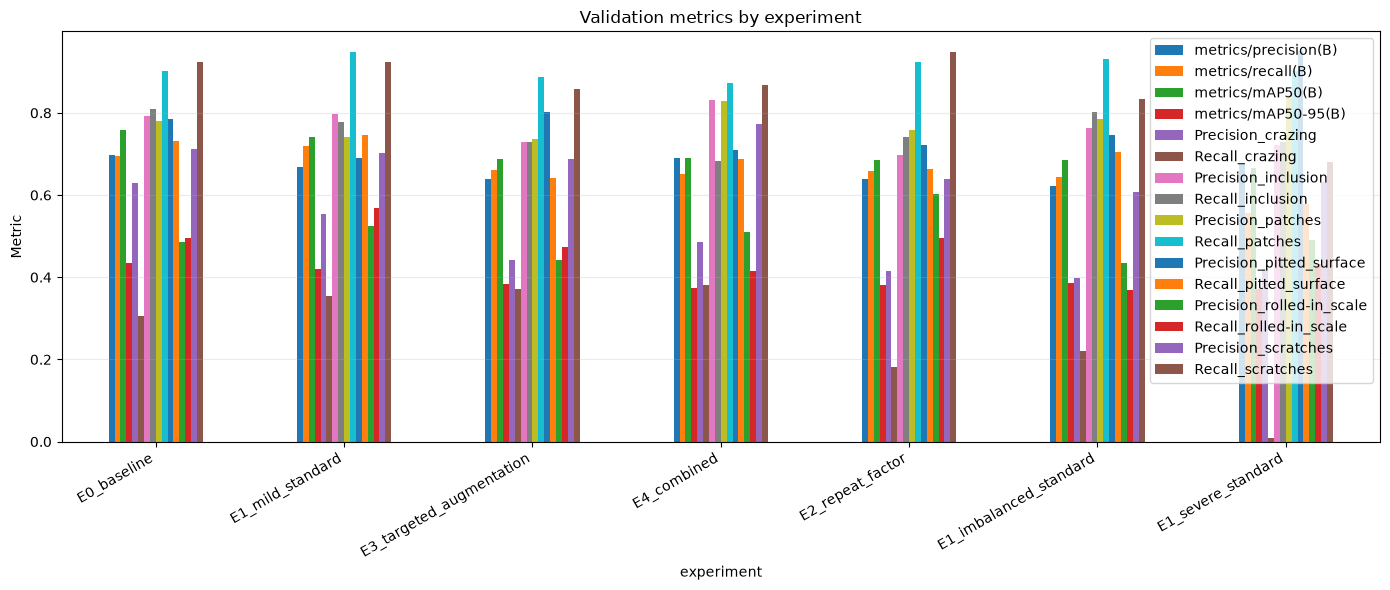

In [2]:
# Assemble a single validation comparison table, including per-class AP50.
comparison_rows = []
if PHASE3_METRICS.is_file():
    baseline = json.loads(PHASE3_METRICS.read_text(encoding="utf-8"))
    baseline_row = {"experiment": "E0_baseline", "checkpoint_sha256": baseline.get("checkpoint_sha256"), **baseline.get("metrics", {})}
    for item in baseline.get("per_class", []):
        baseline_row[f"AP50_{item['class_name']}"] = item.get("ap50")
        baseline_row[f"AP50_95_{item['class_name']}"] = item.get("ap50_95")
        baseline_row[f"Precision_{item['class_name']}"] = item.get("precision")
        baseline_row[f"Recall_{item['class_name']}"] = item.get("recall")
        baseline_row[f"F1_{item['class_name']}"] = item.get("f1")
    baseline_row["macro_F1"] = baseline.get("macro_F1")
    comparison_rows.append(baseline_row)
if PHASE5_METRICS.is_file():
    phase5 = pd.read_csv(PHASE5_METRICS)
    comparison_rows.extend(phase5.to_dict(orient="records"))

MINORITY_CLASSES = ["crazing", "pitted_surface", "rolled-in_scale", "scratches"]
if not comparison_rows:
    raise FileNotFoundError("Run Phase 3 and Phase 5 to create validation metrics before Phase 6.")
comparison = pd.DataFrame(comparison_rows)
comparison["minority_macro_AP50"] = comparison[[f"AP50_{name}" for name in MINORITY_CLASSES]].mean(axis=1)
map50_col = "metrics/mAP50(B)"
if map50_col not in comparison:
    raise KeyError(f"Expected overall validation mAP50 column {map50_col!r}.")
comparison = comparison.dropna(subset=["minority_macro_AP50", map50_col])
if comparison.empty:
    raise ValueError("Per-class AP50 is incomplete; rerun Phase 3 and Phase 5 validation cells.")
comparison = comparison.sort_values(["minority_macro_AP50", map50_col], ascending=False).reset_index(drop=True)
selected = comparison.iloc[0]
comparison["selected_for_final_test"] = comparison["experiment"] == str(selected["experiment"])
COMPARISON_PATH = RESULTS / "validation_model_comparison.csv"
comparison.to_csv(COMPARISON_PATH, index=False)
SELECTED_RUN = str(selected["experiment"])
if SELECTED_RUN == "E0_baseline":
    SELECTED_CHECKPOINT = PROJECT_ROOT / "outputs" / "checkpoints" / "phase3_baseline" / "E0_baseline" / "weights" / "best.pt"
else:
    SELECTED_CHECKPOINT = PROJECT_ROOT / "outputs" / "checkpoints" / "phase5" / SELECTED_RUN / "weights" / "best.pt"
if not SELECTED_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Selected validation checkpoint is missing: {SELECTED_CHECKPOINT}")
selection = {
    "selected_run": SELECTED_RUN,
    "checkpoint": str(SELECTED_CHECKPOINT),
    "checkpoint_sha256": sha256_file(SELECTED_CHECKPOINT),
    "split_manifest_sha256": sha256_file(SPLIT_MANIFEST),
    "validation_comparison": str(COMPARISON_PATH),
    "validation_comparison_sha256": sha256_file(COMPARISON_PATH),
    "selection_split": "val",
    "selection_rule": "highest macro AP50 over minority classes; tie-break by overall mAP50",
    "minority_classes": MINORITY_CLASSES,
    "minority_macro_AP50": float(selected["minority_macro_AP50"]),
    "validation_mAP50": float(selected[map50_col]),
    "validation_mAP50_95": float(selected.get("metrics/mAP50-95(B)", float("nan"))),
    "validation_macro_F1": float(selected.get("macro_F1", float("nan"))),
}
SELECTION_PATH.write_text(json.dumps(selection, indent=2) + "\n", encoding="utf-8")
display(comparison[["experiment", *[f"AP50_{name}" for name in MINORITY_CLASSES], "minority_macro_AP50", map50_col]])
print("Selected from validation:", SELECTED_RUN)
print("Checkpoint:", SELECTED_CHECKPOINT)
print("Selection record:", SELECTION_PATH)

metric_columns = [column for column in comparison.columns if any(
    token in str(column).lower() for token in ("map50", "map50-95", "precision", "recall")
)]
available = [column for column in metric_columns if pd.api.types.is_numeric_dtype(comparison[column])]
if available:
    ax = comparison.set_index("experiment")[available].plot(kind="bar", figsize=(14, 6))
    ax.set_title("Validation metrics by experiment")
    ax.set_ylabel("Metric")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 3. Evaluate the selected model once on the held-out test split

In [3]:
if RUN_FINAL_TEST:
    if not SELECTED_CHECKPOINT.is_file():
        raise FileNotFoundError(f"Selected checkpoint does not exist: {SELECTED_CHECKPOINT}")
    if not DATA_YAML.is_file():
        raise FileNotFoundError(f"Dataset YAML not found: {DATA_YAML}")
    # Make notebook reruns idempotent: never run the test split again for the same checkpoint.
    if FINAL_TEST_PATH.is_file():
        previous = json.loads(FINAL_TEST_PATH.read_text(encoding="utf-8"))
        current_checkpoint_sha256 = sha256_file(SELECTED_CHECKPOINT)
        current_split_sha256 = sha256_file(SPLIT_MANIFEST)
        if (Path(previous.get("checkpoint", "")).resolve() != SELECTED_CHECKPOINT.resolve()
                or previous.get("checkpoint_sha256") != current_checkpoint_sha256
                or previous.get("split_manifest_sha256") != current_split_sha256):
            raise RuntimeError(
                "A held-out test result already exists for different checkpoint or split contents. "
                "Archive the old record before starting a new experiment; do not overwrite it."
            )
        previous.setdefault("test_image_count", sum(
            1 for p in (PROJECT_ROOT / "data" / "processed" / "images" / "test").glob("*") if p.is_file()
        ))
        previous.setdefault("confusion_matrix_labels", [
            "crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches", "background"
        ])
        FINAL_TEST_PATH.write_text(json.dumps(previous, indent=2) + "\n", encoding="utf-8")
        print("Held-out test was already evaluated for this selected checkpoint; reusing saved results.")
        display(pd.DataFrame(previous.get("per_class", [])))
        print("Saved final held-out evaluation:", FINAL_TEST_PATH)
    else:
        try:
            import torch
            from ultralytics import YOLO
        except ImportError as exc:
            raise RuntimeError("Install compatible PyTorch and Ultralytics in the project .venv before test evaluation.") from exc

        model = YOLO(str(SELECTED_CHECKPOINT))
        test_result = model.val(
            data=str(DATA_YAML), split="test", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
            project=str(PROJECT_ROOT / "outputs" / "logs" / "phase6"),
            name=SELECTED_RUN + "_test", exist_ok=True, device=0 if torch.cuda.is_available() else "cpu",
        )
        box = test_result.box
        class_indices = list(getattr(box, "ap_class_index", []))
        class_rows = []
        for position, class_id in enumerate(class_indices):
            class_id = int(class_id)
            class_rows.append({
                "class_id": class_id,
                "class_name": test_result.names[class_id],
                "precision": float(box.p[position]) if len(box.p) > position else None,
                "recall": float(box.r[position]) if len(box.r) > position else None,
                "ap50": float(box.ap50[position]) if len(box.ap50) > position else None,
                "ap50_95": float(box.ap[position].mean()) if len(box.ap) > position else None,
            })
            precision, recall = class_rows[-1]["precision"], class_rows[-1]["recall"]
            class_rows[-1]["f1"] = (2 * precision * recall / (precision + recall)) if precision is not None and recall is not None and precision + recall else 0.0
        global_metrics = {str(k): float(v) for k, v in getattr(test_result, "results_dict", {}).items()}
        global_precision = global_metrics.get("metrics/precision(B)")
        global_recall = global_metrics.get("metrics/recall(B)")
        global_f1 = (2 * global_precision * global_recall / (global_precision + global_recall)) if global_precision is not None and global_recall is not None and global_precision + global_recall else 0.0
        global_metrics["metrics/F1(B)"] = global_f1
        final_record = {
            "selected_run": SELECTED_RUN, "checkpoint": str(SELECTED_CHECKPOINT),
            "checkpoint_sha256": sha256_file(SELECTED_CHECKPOINT),
            "split_manifest_sha256": sha256_file(SPLIT_MANIFEST),
            "evaluated_split": "test", "selection_split": "val",
            "test_image_count": sum(1 for p in (PROJECT_ROOT / "data" / "processed" / "images" / "test").glob("*") if p.is_file()),
            "confusion_matrix_labels": ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches", "background"],
            "selection_rule": "highest macro AP50 over minority classes; tie-break by overall mAP50",
            "global_metrics": global_metrics,
            "macro_F1": sum(row["f1"] for row in class_rows) / max(len(class_rows), 1),
            "test_inference_speed_ms_per_image": getattr(test_result, "speed", {}),
            "confusion_matrix": (test_result.confusion_matrix.matrix.tolist()
                                 if getattr(test_result, "confusion_matrix", None) is not None else None),
            "per_class": class_rows,
        }
        FINAL_TEST_PATH.write_text(json.dumps(final_record, indent=2) + "\n", encoding="utf-8")
        display(pd.DataFrame(class_rows))
        print("Saved final held-out evaluation:", FINAL_TEST_PATH)
else:
    print("Test split not read. Set RUN_FINAL_TEST=True only after validation selection.")

Held-out test was already evaluated for this selected checkpoint; reusing saved results.


,class_id,class_name,precision,recall,ap50,ap50_95,f1
0,0,crazing,0.520047,0.290000,0.382076,0.154741,0.372358
1,1,inclusion,0.718822,0.808140,0.846032,0.461167,0.760868
2,2,patches,0.856980,0.873134,0.938133,0.631125,0.864982
3,3,pitted_surface,0.818328,0.776639,0.854123,0.567802,0.796939
4,4,rolled-in_scale,0.651635,0.600000,0.679548,0.303394,0.624753
5,5,scratches,0.812249,0.905499,0.947883,0.585077,0.856343


Saved final held-out evaluation: ./results/final_test_metrics.json


## Phase 6 reporting

The saved selection record names the checkpoint chosen from validation by minority-class macro AP50, with overall validation mAP50 as the tie-break. The final test report contains per-class precision, recall, AP50, AP50–95, and global mAP. Test metrics do not influence model selection.